In [1]:
# ------------------------------------------------------------
# 0. Librerías
# ------------------------------------------------------------
import os
import warnings
import logging

# Se ocultan los avisos de las librerías para que la salida quede más limpia
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
os.environ["HF_HUB_VERBOSITY"] = "error"

import re
import numpy as np
import random
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from datasets import load_dataset
import optuna
import torch
import torch.nn as nn
from PIL import Image, ImageOps
from torchvision import transforms
from torchvision.models import efficientnet_b0
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Palabras conectoras en inglés y diccionario de sentimiento (VADER) de NLTK
nltk.download("stopwords", quiet=True)
nltk.download("vader_lexicon", quiet=True)

# Semilla para que la elección de respuestas sea la misma en cada ejecución
random.seed(42)

In [2]:
# ------------------------------------------------------------
# 1. Configuración inicial de herramientas NLP
# ------------------------------------------------------------

# Separa el texto en palabras y reduce cada palabra a su raíz (cancel, canceling, cancelled -> cancel)
tokenizer = RegexpTokenizer(r'\w+')
stemmer = SnowballStemmer("english")

# Palabras conectoras que no aportan a la intención (the, my, you, to...)
# Se dejan las negaciones porque cambian el sentido del mensaje
STOPWORDS = set(stopwords.words("english")) - {"no", "not", "nor"}

def normalizar_texto(texto):
    """
    Convierte el texto a minúsculas, elimina acentos y caracteres especiales.
    """
    texto = texto.lower()
    texto = unicodedata.normalize("NFD", texto)
    texto = texto.encode("ascii", "ignore").decode("utf-8")
    texto = re.sub(r"[^a-zñ0-9\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

def tokenizar_y_stem(texto):
    """
    Tokeniza el texto, quita las palabras conectoras y aplica stemming.
    """
    texto = normalizar_texto(texto)
    tokens = [token for token in tokenizer.tokenize(texto) if token not in STOPWORDS]
    stems = [stemmer.stem(token) for token in tokens]
    return tokens, stems

def stems(texto):
    """
    Devuelve solo los stems del texto; es el tokenizador que usan BoW y TF-IDF.
    """
    return tokenizar_y_stem(texto)[1]

# Ejemplo del preprocesamiento completo: normalización, tokenización, stopwords y stemming
print(tokenizar_y_stem("I want to EXCHANGE my Jackets, please!"))

(['want', 'exchange', 'jackets', 'please'], ['want', 'exchang', 'jacket', 'pleas'])


In [3]:
# ------------------------------------------------------------
# 2. Carga, limpieza y división del Bitext Customer Support Dataset
# ------------------------------------------------------------

# Cargando base de datos desde Hugging Face
ds = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")
df = ds["train"].to_pandas()

# Limpieza de valores faltantes y espacios sobrantes
df = df.dropna(subset=["instruction", "intent", "response"])
for col in ["instruction", "category", "intent", "response", "flags"]:
    df[col] = df[col].astype(str).str.strip()

# Una misma consulta puede repetirse con respuestas distintas,
# así que se conserva una vez cada par consulta-intención
df = df.drop_duplicates(subset=["instruction", "intent"]).reset_index(drop=True)

# Split 80/20 por intención: el 80 % se usa para entrenar el modelo y armar las
# intenciones, y el 20 % para probar con mensajes que el chatbot no conoce.
# random_state fija la división para que siempre salga igual
PORCENTAJE_PRUEBA = 0.2
prueba = df.groupby("intent", group_keys=False).sample(frac=PORCENTAJE_PRUEBA, random_state=42)
entrenamiento = df.drop(prueba.index)

print(f"Categorías: {df['category'].nunique()} | Intenciones: {df['intent'].nunique()}")

Categorías: 11 | Intenciones: 27


In [4]:
# ------------------------------------------------------------
# 2.1 Base de conocimiento: datos de la tienda
# ------------------------------------------------------------
# Datos de la tienda que se insertan en las respuestas con .format()

DATOS_TIENDA = {
    "website": "www.ourstore.com",
    "support_email": "support@ourstore.com",
    "support_phone": "1-800-555-0123",
    "support_hours": "Monday to Friday, 9 a.m. to 6 p.m. (CT)",
    "standard_shipping": "5 to 7 business days",
    "express_shipping": "2 to 3 business days",
    "free_shipping_min": "$75",
    "return_window": "30 days",
    "refund_time": "5 to 10 business days",
    "cancellation_window": "before your order ships",
    "cancellation_fee": "no fee",
}

In [5]:
# ------------------------------------------------------------
# 2.2 Base de conocimiento: respuestas por intención
# ------------------------------------------------------------
# Intenciones que no resuelve el chatbot y se canalizan a un agente humano
INTENCIONES_SENSIBLES = {"complaint", "payment_issue", "contact_human_agent", "delete_account"}

# Dos respuestas por intención; los marcadores {website}, {refund_time}, etc.
# se reemplazan con DATOS_TIENDA al momento de responder
RESPUESTAS = {
    # ACCOUNT
    "create_account": [
        "Happy to help you get started! Just go to {website}, click on 'Sign up' and fill in your name, email and a password. It only takes a minute.",
        "Creating an account is quick and easy. Head over to {website}, choose 'Sign up' and follow the steps. Once you're in, you'll be able to track your orders and save your addresses.",
    ],
    "delete_account": [
        "I'm sorry to see you go. To make sure everything is handled safely, I'll connect you with a member of our team who can help you close your account.",
        "Thanks for letting us know. Account deletion needs to be confirmed by our support team, so I'm passing your request to an agent who will reach out shortly.",
    ],
    "edit_account": [
        "Sure thing! Sign in at {website}, go to 'My account' and click 'Edit profile' to update your details. Don't forget to save your changes.",
        "You can update your name, email or phone number anytime from 'My account' at {website}. Just click 'Edit profile' and save when you're done.",
    ],
    "recover_password": [
        "No worries, it happens! Go to {website}, click 'Sign in' and then 'Forgot password'. We'll send you an email with a link to create a new one.",
        "Let's get you back in. Click 'Forgot password' on the sign-in page at {website} and check your inbox for the reset link. If you don't see it, take a look at your spam folder.",
    ],
    "registration_problems": [
        "Sorry you're having trouble signing up. Please make sure your email isn't already registered and that your password has at least 8 characters. If it still doesn't work, write to us at {support_email} and we'll sort it out.",
        "That's frustrating, let's fix it. Try refreshing the page or using a different browser. If the problem continues, our team can help you at {support_email}.",
    ],
    "switch_account": [
        "To switch accounts, just sign out from 'My account' at {website} and sign back in with the other email.",
        "Sure! Sign out of your current account and then sign in with the one you'd like to use. Your orders and addresses stay saved in each account.",
    ],
    # CANCEL
    "check_cancellation_fee": [
        "Good news, there's {cancellation_fee} for canceling an order as long as you do it {cancellation_window}.",
        "Canceling an order has {cancellation_fee} if it's done {cancellation_window}. If it has already shipped, you can return it within {return_window} instead.",
    ],
    # CONTACT
    "contact_customer_service": [
        "You can reach our customer service team at {support_email} or call us at {support_phone}, {support_hours}.",
        "We're happy to help! Write to us at {support_email} or give us a call at {support_phone}. Our hours are {support_hours}.",
    ],
    "contact_human_agent": [
        "Of course! I'm connecting you with one of our agents right now. They'll be able to see our conversation, so you won't have to repeat anything.",
        "Sure, let me pass you to a member of our team. Please hold on for a moment while an agent joins the chat.",
    ],
    # DELIVERY
    "delivery_options": [
        "We offer standard shipping ({standard_shipping}) and express shipping ({express_shipping}). Standard shipping is free on orders over {free_shipping_min}.",
        "You can choose between standard delivery, which takes {standard_shipping}, and express delivery, which takes {express_shipping}. You'll see both options at checkout.",
    ],
    "delivery_period": [
        "Standard orders usually arrive in {standard_shipping}, and express orders in {express_shipping}. You'll get a tracking link by email as soon as your order ships.",
        "Delivery times depend on the option you chose: {standard_shipping} for standard shipping and {express_shipping} for express. You can check the status anytime under 'My orders'.",
    ],
    # FEEDBACK
    "complaint": [
        "I'm really sorry about your experience. I want to make sure this gets the attention it deserves, so I'm connecting you with a member of our team.",
        "Thanks for telling us, and I'm sorry things didn't go as expected. An agent will join the chat shortly to help you resolve it.",
    ],
    "review": [
        "We'd love to hear your thoughts! You can leave a review on the product page at {website}, under 'Write a review'.",
        "Thanks for wanting to share your opinion! Just go to the product page, scroll down to 'Reviews' and tell us what you think.",
    ],
    # INVOICE
    "check_invoice": [
        "You can find all your invoices in 'My account' > 'My orders' at {website}. Just select the order you need.",
        "Sure! Sign in at {website}, go to 'My orders' and click on the order to see its invoice.",
    ],
    "get_invoice": [
        "To download your invoice, go to 'My orders' at {website}, open the order and click 'Download invoice'.",
        "No problem! Your invoice is available as a PDF in 'My orders'. If you can't find it, write to us at {support_email} and we'll send it to you.",
    ],
    # SUBSCRIPTION
    "newsletter_subscription": [
        "Want to hear about new arrivals and special offers? Just enter your email at the bottom of {website} and click 'Subscribe'.",
        "You can subscribe or unsubscribe anytime. To join, add your email at the bottom of our page, and to leave, click 'Unsubscribe' in any of our emails.",
    ],
    # ORDER
    "cancel_order": [
        "You can cancel your order {cancellation_window}. Go to 'My orders' at {website}, select the order and click 'Cancel order'.",
        "Sure, I can help with that. Open 'My orders', choose the order you want to cancel and click 'Cancel order'. If it has already shipped, you can return it within {return_window}.",
    ],
    "change_order": [
        "If your order hasn't shipped yet, you can change it from 'My orders' at {website}. Just open the order and click 'Edit order'.",
        "Happy to help! Changes like size, color or quantity can be made {cancellation_window} from 'My orders'. If it's already on its way, you can return or exchange it once it arrives.",
    ],
    "place_order": [
        "Placing an order is easy! Add the items you like to your cart at {website}, click 'Checkout' and follow the steps to choose your shipping and payment method.",
        "Just pick your items, choose your size and add them to your cart. When you're ready, click 'Checkout' to complete your purchase.",
    ],
    "track_order": [
        "You can track your order from 'My orders' at {website}. We also sent you a tracking link by email when your order shipped.",
        "Sure! Sign in at {website} and go to 'My orders' to see where your package is. Standard orders usually arrive in {standard_shipping}.",
    ],
    # PAYMENT
    "check_payment_methods": [
        "We accept Visa, Mastercard, American Express, PayPal and Apple Pay.",
        "You can pay with any major credit or debit card, PayPal or Apple Pay. You'll see all the options at checkout.",
    ],
    "payment_issue": [
        "I'm sorry you're having trouble with your payment. Since this involves your billing details, I'm connecting you with an agent who can review it safely.",
        "Thanks for letting us know. Payment issues need to be checked by our team, so I'm passing you to an agent who will help you right away.",
    ],
    # REFUND
    "check_refund_policy": [
        "You can return any item within {return_window} of delivery for a full refund, as long as it's unworn and has its tags.",
        "Our refund policy is simple: items can be returned within {return_window} in their original condition, and the refund goes back to your original payment method.",
    ],
    "get_refund": [
        "To request a refund, go to 'My orders' at {website}, select the order and click 'Return item'. Once we receive it, your refund will be processed in {refund_time}.",
        "Sure! Start a return from 'My orders' and send the item back within {return_window}. We'll issue your refund as soon as it reaches us.",
    ],
    "track_refund": [
        "Refunds usually take {refund_time} to show up after we receive your return. You can check the status in 'My orders' at {website}.",
        "Your refund is processed once your return arrives at our warehouse, and it may take {refund_time} to appear in your account. You can follow its status in 'My orders'.",
    ],
    # EXCHANGE (intención nueva, no viene en el dataset)
    "exchange_item": [
        "Of course! You can exchange any item within {return_window} of delivery for a different size or color. Go to 'My orders' at {website}, select the {prenda} and click 'Exchange item'. Exchanges are free as long as it's unworn and has its tags.",
        "No problem! Just start an exchange from 'My orders', choose the new size or color, and send us the {prenda} within {return_window}. We'll ship the new one as soon as we receive it.",
    ],
    # IMAGE (intención nueva para el componente visual)
    "classify_image": [
        "Sure! Please type the path of the image you want me to check, for example imagenes_prueba/dress_1.png.",
        "Of course, I can help with that. Type the path of the photo of the item and I'll tell you what it is.",
    ],
    # SHIPPING
    "change_shipping_address": [
        "If your order hasn't shipped yet, you can update the address from 'My orders' at {website}. For future orders, you can change it in 'My account' > 'Addresses'.",
        "Sure! Go to 'My account' > 'Addresses' to update it. If you need to change the address of an order that's already on its way, please contact us at {support_email}.",
    ],
    "set_up_shipping_address": [
        "To add a shipping address, sign in at {website}, go to 'My account' > 'Addresses' and click 'Add new address'.",
        "You can save one or more addresses in 'My account' > 'Addresses', so they're ready to choose at checkout.",
    ],
}

In [6]:
# ------------------------------------------------------------
# 2.3 Ejemplos del sector de ropa
# ------------------------------------------------------------
# El dataset de Bitext es genérico, así que se agregan ejemplos escritos a mano con
# tallas, colores, prendas, cambios de producto, quejas indirectas, envíos y pagos.
# EJEMPLOS_ROPA se suma al entrenamiento y PRUEBA_ROPA se usa solo para evaluar,
# de forma que el modelo nunca ve estas frases de prueba al entrenar.

EJEMPLOS_ROPA = {
    # Intención nueva: el cliente quiere que el chatbot identifique una prenda en una imagen
    "classify_image": [
        "can you identify an item from a photo?",
        "I want to upload a picture of a product",
        "what is the item in this image?",
        "can you tell me what clothing this is from a picture",
        "I have a photo of something I want to buy",
        "identify this garment from my picture",
        "I want to send you an image",
        "can you recognize a product in a photo?",
        "check this image please",
        "I'd like to classify an image",
        "what kind of item is in my photo",
        "can I show you a picture of what I'm looking for",
        "I want to search a product with a photo",
        "here is a photo, what is it?",
        "analyze this picture of my clothes",
        "can you look at an image for me",
        "I took a picture of the item I received",
        "find this item from an image",
        "use my photo to identify the product",
        "what type of clothing appears in this picture",
        "image recognition",
        "identify image",
        "I want to know what this item is, I have a photo",
        "can you tell what's in the photo I have",
        "recognize the clothes in my image",
    ],
    # Intención nueva: cambio de una prenda por otra talla o color
    "exchange_item": [
        "I want to exchange my shirt for a bigger size",
        "can I swap these jeans for a smaller size?",
        "the dress is too tight, I need a larger one",
        "I'd like to exchange my jacket for a different color",
        "how do I exchange an item?",
        "can I change the hoodie I received for a medium?",
        "these sneakers are too big, can I get a size smaller?",
        "I need to exchange the blouse, it doesn't fit",
        "I want the same pants but in black",
        "exchange size L for size M",
        "the sweater I got is too small, can I exchange it",
        "I want to trade my coat for another size",
        "can I get a different size of the skirt I bought",
        "how can I exchange shoes that don't fit",
        "I ordered a size S but I need an XL, can I swap it?",
        "is it possible to exchange a product for another color",
        "I received the boots but want them in brown instead",
        "do you do exchanges for clothes that don't fit?",
        "I want to replace my t-shirt with a bigger one",
        "can I exchange a gift I received from your store?",
        "the leggings are too long, can I exchange them for a shorter size",
        "I want to change the jeans I got for a different fit",
        "exchange item",
        "size exchange",
        "I need another size for the dress I received",
        "I bought a medium but it's too loose, can I get a small?",
        "can you send me the same hoodie in a large?",
        "my daughter needs the dress in a smaller size, can we exchange it",
        "I'd like a different color for the sweater I received",
        "the shoes are half a size too small, I need to exchange them",
        "exchange the gray t-shirt for the white one",
        "can I get these trousers in a longer length",
        "I need to change the size of the jacket I got last week",
        "what's the process to swap clothes for another size",
        "the blouse looks different in person, I'd prefer the blue one",
        "can I exchange an item bought on sale?",
        "I want to switch my sneakers for a bigger pair",
        "how long do I have to exchange a coat?",
        "I received a size 10 and need a size 12",
        "the skirt is too short, I want the next size",
        "can I exchange something I bought online in your store?",
        "I'd like to exchange the boots for another model",
        "swap my jeans for a regular fit",
        "is there a charge to exchange sizes?",
        "I want a replacement in a different size",
    ],
    # Cambios a un pedido que todavía no se envía
    "change_order": [
        "I want to change the size of my order before it ships",
        "can I change the color of the shirt I just ordered?",
        "I ordered the wrong size, can I fix it before shipping?",
        "please change the jacket in my order to a large",
        "I want to add another pair of jeans to my order",
        "can I remove the hat from my order?",
        "I picked the wrong color in my order",
        "update the quantity of t-shirts in my last purchase",
        "I need to modify my order, I chose medium instead of small",
        "change my order from blue to black",
        "can I switch the dress in my order to a size 8",
        "I want to change an item in the order I placed today",
        "my order has the wrong size and it hasn't shipped yet",
        "can I still edit my order?",
        "replace the sneakers in my order with the boots",
        "I made a mistake with the size in the order I just placed",
        "can I change the shoes in my order to a size 9?",
        "please switch the hoodie in my order to gray",
        "I want to update my order before you send it",
        "add a scarf to my current order",
        "I ordered two dresses but I only want one",
        "change the size of the pants in my pending order",
        "I need to correct the color I chose for my order",
        "can I modify the items in my order?",
        "remove one t-shirt from my order please",
        "I want a different size in the order I made an hour ago",
        "my order isn't shipped yet, can I change the jacket for a coat?",
    ],
    # Devoluciones de prendas con reembolso
    "get_refund": [
        "I want to return the dress I bought and get my money back",
        "how do I return a jacket that doesn't fit?",
        "I'd like a refund for the jeans",
        "can I send back the shoes and get a refund?",
        "the shirt arrived damaged, I want my money back",
        "return the sweater I ordered",
        "I want to return two items from my order",
        "how can I get a refund for the coat I returned",
        "I don't like the color, I want to return it",
        "I want my money back for the skirt",
        "start a return for my order",
        "I need to return a gift and get a refund",
        "how do I send back clothes I don't want",
        "refund for the hoodie please",
        "I changed my mind about the pants, can I return them?",
        "I'd like to return my sneakers, they hurt my feet",
        "how do I get my money back for clothes that don't fit",
        "I want to return the whole order",
        "can I return the shirt and get a refund to my card?",
        "the jacket is too big, I just want my money back",
        "I want to return a coat I bought on sale",
        "I need a refund for the damaged boots",
        "how do I print a return label for my sweater",
        "I'd like to return these leggings",
        "refund the blouse, it's not what I expected",
        "I want to give back the shoes and get a refund",
        "process a return for the hat I ordered",
        "I don't want the skirt anymore, can I get a refund?",
        "how do I return clothes bought online?",
        "return and refund for the hoodie I received",
    ],
    # Quejas indirectas, sin palabras como "complaint" o "claim"
    "complaint": [
        "the shirt I got is completely different from the picture",
        "I received a jacket with a broken zipper",
        "this is the third time my order arrives wrong",
        "the dress faded after one wash",
        "my package arrived open and the shoes were dirty",
        "I've been waiting two weeks and nobody answers my emails",
        "the quality of these jeans is terrible",
        "I got the wrong item and I'm very disappointed",
        "your delivery guy left my package in the rain",
        "the sweater has a hole in it",
        "I'm not happy with how I was treated by your support team",
        "the size chart is wrong and now nothing fits",
        "I keep getting emails I never asked for, this is annoying",
        "I paid for express shipping and it still arrived late",
        "the colors look nothing like the website",
        "I want to report a problem with the quality of my order",
        "I am disappointed with my last purchase",
        "the stitching on my pants came apart",
        "my sweater shrank after the first wash",
        "the buttons on my coat fell off",
        "the fabric started pilling after a week",
        "the shoes smell weird and look used",
        "the dress I received is not the one I ordered",
        "my order came with missing items",
        "your customer service agent was rude to me",
        "the jeans ripped the second time I wore them",
        "I've asked three times about my order and still no answer",
        "the color of the shirt bled onto my other clothes",
        "the delivery was a week late and the box was crushed",
        "the jacket looks nothing like the photos",
        "I'm very unhappy with the hoodie I received",
        "the seams on my dress are coming apart",
        "this is unacceptable, my package was lost",
        "I received a used item",
        "the size is completely different from your size chart",
        "the boots started peeling after a few days",
        "I'm tired of waiting for a solution",
        "the quality is much worse than what I expected",
    ],
    # Seguimiento de pedidos mencionando prendas
    "track_order": [
        "where is my jacket?",
        "my jeans haven't arrived yet",
        "when will my dress arrive?",
        "has my order of shoes shipped?",
        "I'm waiting for my sweater, where is it",
        "can you tell me where my package is",
        "I want to know the status of the shirts I bought",
        "tracking number for my last order",
        "is my order on the way?",
        "my hoodie still hasn't shipped",
        "when do I get the boots I ordered",
        "check where my clothes are",
        "has my jacket left the warehouse?",
        "I ordered shoes ten days ago and nothing yet",
        "can you check the status of my dress order",
        "where is the package with my jeans",
        "when is my coat going to be delivered",
        "is my sweater on its way?",
        "track my clothing order",
        "my t-shirts were supposed to arrive yesterday",
        "I want to follow my order of boots",
        "what's the delivery status of my skirt",
        "do you know when my order will get here",
        "show me where my hoodie is",
    ],
    # Compras mencionando prendas
    "place_order": [
        "I want to buy these jeans",
        "how do I order a dress in size M?",
        "I'd like to purchase a black jacket",
        "can I order two shirts?",
        "I'd like to order some sneakers",
        "how can I buy something from your store",
        "I'd like to get the blue hoodie",
        "help me buy a coat",
        "I want to order a gift for my sister",
        "add the skirt to my cart and buy it",
        "I'm ready to buy, how do I check out?",
        "can I order online and pick a size?",
        "I want to buy the black boots in size 8",
        "can I buy the red dress online?",
        "I'd like to order a hoodie in XL",
        "how can I make a purchase on your website",
        "I want to get two pairs of leggings",
        "please help me order a winter coat",
        "I'd like to buy a matching shirt and pants",
        "where do I click to buy the sweater",
        "I want to purchase the denim jacket",
        "how do I order shoes in my size",
        "can I place an order for a t-shirt in white",
        "I'm interested in buying the scarf",
    ],
    # Política de devoluciones de ropa
    "check_refund_policy": [
        "can I return clothes I already wore?",
        "do I need the tags to return an item?",
        "how many days do I have to return a dress?",
        "what is your return policy for shoes?",
        "can I return sale items?",
        "is there a time limit to return clothes?",
        "do you refund shipping costs on returns?",
        "what are the conditions to return a garment",
        "what is the return window for clothes?",
        "can I return shoes that I tried on at home?",
        "are returns free?",
        "can I return swimwear?",
        "what happens if I return an item without the box",
        "do you accept returns after 30 days?",
        "is there a fee to return clothes?",
        "what's your policy for returning damaged clothes",
        "do I get a full refund if I return a dress?",
        "can I return items bought with a discount code?",
    ],
    # Cargo por cancelar un pedido
    "check_cancellation_fee": [
        "will I be charged if I cancel?",
        "is canceling my order free?",
        "how much does it cost to cancel an order",
        "do you charge anything for cancelling a purchase",
        "is there a cancellation charge for clothing orders",
        "do I pay a penalty if I cancel my jacket order",
        "what does it cost me to cancel?",
        "any charge for canceling before shipping?",
        "do you charge to cancel a clothing order?",
        "is there any cost if I cancel my dress order?",
        "will cancelling my order today cost me anything?",
        "what is the cancellation fee?",
        "do I lose money if I cancel?",
        "is cancellation free before the order ships?",
        "how much will you charge me if I cancel the jacket",
        "are there fees for cancelling a purchase",
    ],
    # Tiempos de entrega de prendas
    "delivery_period": [
        "how long will my dress take to arrive?",
        "when will the shoes be delivered if I order today?",
        "how many days does shipping take for clothes",
        "how fast can I get a jacket delivered",
        "how long is standard delivery?",
        "how many business days for clothes to arrive?",
        "when can I expect the sneakers if I buy them today",
        "how quickly do you deliver orders?",
        "how long does it take to receive a jacket",
        "what is the delivery time for a dress",
        "if I order now, when will I get it?",
        "how many days does express delivery take for shoes",
        "how long until a sweater arrives?",
    ],
    # Opciones de envío
    "delivery_options": [
        "what shipping methods do you offer for clothes?",
        "do you offer free shipping?",
        "can I get my jeans delivered faster?",
        "is there next day delivery?",
        "what delivery options are there for my order",
        "do you ship clothes internationally?",
        "how much does shipping cost?",
        "do you have standard and express shipping?",
    ],
    # Cancelación de pedidos de ropa
    "cancel_order": [
        "I want to cancel the jacket I ordered",
        "please cancel my order of shoes",
        "I don't want the dress anymore, cancel my order",
        "cancel the jeans I bought this morning",
        "how do I cancel an order I just placed",
        "I need to cancel my purchase of a coat",
        "stop my order, I ordered by mistake",
        "cancel my hoodie order before it ships",
    ],
    # Métodos de pago
    "check_payment_methods": [
        "do you accept debit cards?",
        "can I use paypal to buy shoes?",
        "what cards do you take?",
        "is it possible to pay in installments?",
        "can I pay with a gift card?",
        "which payment options are available at checkout",
        "do you take american express?",
        "can I pay cash on delivery?",
    ],
    # Problemas con el pago de una compra
    "payment_issue": [
        "my card was declined when buying a dress",
        "I was charged twice for my jeans",
        "the payment failed but the money left my account",
        "I can't complete the payment for my order",
        "there's an error when I try to pay",
        "I was charged the wrong amount for my jacket",
        "checkout keeps rejecting my card",
        "I paid but my order says payment pending",
    ],
}


# Conjunto de prueba del sector de ropa: frases distintas a las de entrenamiento
PRUEBA_ROPA = [
    ("could you identify something from a photo for me?", "classify_image"),
    ("I have an image, can you tell me what product it is?", "classify_image"),
    ("I want to show you a picture", "classify_image"),
    ("please classify a photo of an item", "classify_image"),
    ("this coat is too big, can I get a medium instead?", "exchange_item"),
    ("can I exchange the red sweater for a blue one?", "exchange_item"),
    ("the jeans don't fit, I'd like another size", "exchange_item"),
    ("how do exchanges work for shoes?", "exchange_item"),
    ("I need to swap my dress for a larger size", "exchange_item"),
    ("the t-shirt is small, can I change it for a large", "exchange_item"),
    ("I just ordered the wrong color, can I change it before you ship it?", "change_order"),
    ("please update my order to size L", "change_order"),
    ("can I add a belt to the order I placed this morning?", "change_order"),
    ("I selected the wrong size on my purchase and it hasn't been sent", "change_order"),
    ("I want to send back the boots and get a refund", "get_refund"),
    ("how do I return a skirt I don't like?", "get_refund"),
    ("I'd like my money back for the hoodie", "get_refund"),
    ("return the jacket and refund me", "get_refund"),
    ("the jacket arrived with a stain on it", "complaint"),
    ("my shoes came in the wrong color and I'm disappointed", "complaint"),
    ("the material of the shirt is really cheap", "complaint"),
    ("nobody has replied to my messages in a week", "complaint"),
    ("the zipper of my coat broke the first day", "complaint"),
    ("where are the sneakers I ordered last week?", "track_order"),
    ("my coat hasn't arrived", "track_order"),
    ("has my dress shipped yet?", "track_order"),
    ("what's the status of my clothes order", "track_order"),
    ("I want to buy a pair of jeans in size 32", "place_order"),
    ("how can I order the green dress?", "place_order"),
    ("I'd like to purchase a sweater", "place_order"),
    ("can I return a shirt without tags?", "check_refund_policy"),
    ("how long do I have to return shoes?", "check_refund_policy"),
    ("do you accept returns on sale clothes?", "check_refund_policy"),
    ("does it cost anything to cancel my order?", "check_cancellation_fee"),
    ("am I charged if I cancel my purchase?", "check_cancellation_fee"),
    ("will cancelling cost me money?", "check_cancellation_fee"),
    ("how many days until my jacket arrives?", "delivery_period"),
    ("when would a dress arrive if I buy it now?", "delivery_period"),
    ("I can't remember my password", "recover_password"),
    ("can I pay with apple pay?", "check_payment_methods"),
    ("I want to speak to someone", "contact_human_agent"),
    ("do you have express shipping?", "delivery_options"),
    ("these boots are too narrow, can I get a wider size?", "exchange_item"),
    ("I'd like the hoodie in green instead of black", "exchange_item"),
    ("is it possible to swap a size M for an S?", "exchange_item"),
    ("how can I exchange pants that are too long?", "exchange_item"),
    ("I want to change the size in my order, it hasn't shipped", "change_order"),
    ("can I replace the shirt in my order with a polo?", "change_order"),
    ("please add another pair of socks to my order", "change_order"),
    ("I want to return these sneakers for a refund", "get_refund"),
    ("how do I send back a dress that doesn't fit and get my money?", "get_refund"),
    ("please refund me for the sweater", "get_refund"),
    ("the hoodie came with a big stain", "complaint"),
    ("the button of my jacket broke off immediately", "complaint"),
    ("I'm very upset, my order arrived late and damaged", "complaint"),
    ("the dress I got looks old and worn", "complaint"),
    ("your shoes fell apart after two weeks", "complaint"),
    ("where is my order of jeans?", "track_order"),
    ("my boots have not been delivered yet", "track_order"),
    ("is my jacket order on its way?", "track_order"),
    ("I want to buy the white sneakers", "place_order"),
    ("how can I order a hoodie online?", "place_order"),
    ("I'd like to purchase two t-shirts", "place_order"),
    ("can I return a dress after wearing it once?", "check_refund_policy"),
    ("what's the deadline to return clothes?", "check_refund_policy"),
    ("is there a penalty for cancelling my order?", "check_cancellation_fee"),
    ("will you charge me to cancel the sneakers?", "check_cancellation_fee"),
    ("cancel my order for the black coat", "cancel_order"),
    ("I need to cancel the dress I bought yesterday", "cancel_order"),
    ("how long will the boots take to get here?", "delivery_period"),
    ("when should I expect my clothes?", "delivery_period"),
    ("what shipping options are there?", "delivery_options"),
    ("do you deliver the next day?", "delivery_options"),
    ("do you accept visa?", "check_payment_methods"),
    ("can I pay with paypal?", "check_payment_methods"),
    ("my card got declined at checkout", "payment_issue"),
    ("you charged me twice for one shirt", "payment_issue"),
    ("I want to write a review about the jeans", "review"),
    ("please connect me with a human", "contact_human_agent"),
]


print(f"Ejemplos nuevos para entrenamiento: {sum(len(v) for v in EJEMPLOS_ROPA.values())}")
print(f"Frases del conjunto de prueba de ropa: {len(PRUEBA_ROPA)}")

# Se agregan los ejemplos nuevos al conjunto de entrenamiento
CATEGORIA_INTENCION = df.groupby("intent")["category"].first().to_dict()
CATEGORIA_INTENCION["exchange_item"] = "EXCHANGE"
CATEGORIA_INTENCION["classify_image"] = "IMAGE"

ejemplos_ropa = pd.DataFrame(
    [{"instruction": texto, "intent": intent, "category": CATEGORIA_INTENCION[intent]}
     for intent, textos in EJEMPLOS_ROPA.items() for texto in textos]
)
entrenamiento_ampliado = pd.concat([entrenamiento, ejemplos_ropa], ignore_index=True)

prueba_ropa = pd.DataFrame(PRUEBA_ROPA, columns=["instruction", "intent"])
prueba_ropa["category"] = prueba_ropa["intent"].map(CATEGORIA_INTENCION)

print(f"Entrenamiento ampliado: {len(entrenamiento_ampliado)} frases")

Ejemplos nuevos para entrenamiento: 292
Frases del conjunto de prueba de ropa: 79
Entrenamiento ampliado: 20000 frases


In [7]:
# ------------------------------------------------------------
# 2.4 Diccionario de intenciones
# ------------------------------------------------------------
# Cada intención guarda su categoría, la acción que define la regla,
# sus ejemplos (entrenamiento ampliado) y sus respuestas

intenciones = {}
for intent, grupo in entrenamiento_ampliado.groupby("intent"):
    intenciones[intent] = {
        "categoria": grupo["category"].iloc[0],
        "accion": "canalizar_agente" if intent in INTENCIONES_SENSIBLES else "respuesta_automatica",
        "ejemplos": grupo["instruction"].tolist(),
        "respuestas": RESPUESTAS.get(intent, []),
    }

print(f"Categorías: {len({d['categoria'] for d in intenciones.values()})} | Intenciones: {len(intenciones)}")

# Resumen de las intenciones definidas
resumen_intenciones = pd.DataFrame([
    {"categoria": d["categoria"], "intencion": i, "ejemplos": len(d["ejemplos"]),
     "respuestas": len(d["respuestas"]), "accion": d["accion"]}
    for i, d in intenciones.items()
]).sort_values(["categoria", "intencion"]).reset_index(drop=True)

resumen_intenciones

Categorías: 13 | Intenciones: 29


,categoria,intencion,ejemplos,respuestas,accion
0,ACCOUNT,create_account,714,2,respuesta_automatica
1,ACCOUNT,delete_account,734,2,canalizar_agente
2,ACCOUNT,edit_account,622,2,respuesta_automatica
3,ACCOUNT,recover_password,796,2,respuesta_automatica
4,ACCOUNT,registration_problems,799,2,respuesta_automatica
5,ACCOUNT,switch_account,690,2,respuesta_automatica
6,CANCEL,check_cancellation_fee,776,2,respuesta_automatica
7,CONTACT,contact_customer_service,800,2,respuesta_automatica
8,CONTACT,contact_human_agent,799,2,canalizar_agente
9,DELIVERY,delivery_options,536,2,respuesta_automatica


In [8]:
# ------------------------------------------------------------
# 3. Representación del texto: Bag of Words y TF-IDF
# ------------------------------------------------------------
# Ambas usan el preprocesamiento de la sección 1 como tokenizador.
# Bag of Words cuenta cuántas veces aparece cada stem en el mensaje.
# TF-IDF le da más peso a los stems frecuentes en el mensaje pero poco comunes en el resto.

bow = CountVectorizer(tokenizer=stems, lowercase=False, token_pattern=None)
tfidf = TfidfVectorizer(tokenizer=stems, lowercase=False, token_pattern=None)

# El vocabulario se aprende solo con el entrenamiento ampliado
X_bow = bow.fit_transform(entrenamiento_ampliado["instruction"])
X_tfidf = tfidf.fit_transform(entrenamiento_ampliado["instruction"])
y_entrenamiento = entrenamiento_ampliado["intent"]

print(f"Tamaño del vocabulario: {len(bow.vocabulary_)} stems")
print(f"Matriz Bag of Words: {X_bow.shape[0]} frases x {X_bow.shape[1]} stems")
print(f"Matriz TF-IDF: {X_tfidf.shape[0]} frases x {X_tfidf.shape[1]} stems")

# Ejemplo de cómo queda un mensaje con cada representación
mensaje_ejemplo = "I want to exchange my jacket for a bigger size"
v_bow = bow.transform([mensaje_ejemplo])
v_tfidf = tfidf.transform([mensaje_ejemplo])

pd.DataFrame({
    "stem": bow.get_feature_names_out()[v_bow.indices],
    "bag_of_words": v_bow.data,
    "tf_idf": [round(v_tfidf[0, i], 3) for i in v_bow.indices],
}).sort_values("tf_idf", ascending=False).reset_index(drop=True)

Tamaño del vocabulario: 2384 stems
Matriz Bag of Words: 20000 frases x 2384 stems
Matriz TF-IDF: 20000 frases x 2384 stems


,stem,bag_of_words,tf_idf
0,bigger,1,0.569
1,jacket,1,0.476
2,exchang,1,0.467
3,size,1,0.443
4,want,1,0.185


In [9]:
# ------------------------------------------------------------
# 4. Entrenamiento y selección del clasificador
# ------------------------------------------------------------
# Se comparan Naive Bayes y SVM con cada representación mediante validación cruzada
# de 5 partes sobre el entrenamiento ampliado, de forma que la elección del modelo
# no usa las frases de prueba.

def nuevo_bow():
    return CountVectorizer(tokenizer=stems, lowercase=False, token_pattern=None)

def nuevo_tfidf():
    return TfidfVectorizer(tokenizer=stems, lowercase=False, token_pattern=None)

# Modelos candidatos: nombre -> (representación, clasificador)
CANDIDATOS = {
    "Naive Bayes + Bag of Words": (nuevo_bow, MultinomialNB),
    "Naive Bayes + TF-IDF": (nuevo_tfidf, MultinomialNB),
    "SVM + Bag of Words": (nuevo_bow, LinearSVC),
    "SVM + TF-IDF": (nuevo_tfidf, LinearSVC),
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Marca qué frases del entrenamiento son los ejemplos del sector de ropa
es_ejemplo_ropa = entrenamiento_ampliado.index >= len(entrenamiento)

resultados_validacion = []
for nombre, (crear_vectorizador, clasificador) in CANDIDATOS.items():
    # Cada parte se predice con un modelo entrenado con las otras cuatro
    pred = cross_val_predict(make_pipeline(crear_vectorizador(), clasificador()),
                             entrenamiento_ampliado["instruction"], y_entrenamiento, cv=validacion)
    f1_validacion = f1_score(y_entrenamiento, pred, average="macro")
    exactitud_ropa = accuracy_score(y_entrenamiento[es_ejemplo_ropa], pred[es_ejemplo_ropa])
    resultados_validacion.append({
        "modelo": nombre,
        "f1_macro_validacion": f1_validacion,
        "exactitud_ejemplos_ropa": exactitud_ropa,
        # Puntaje final: promedio del F1 general y del desempeño con mensajes de ropa
        "puntaje": (f1_validacion + exactitud_ropa) / 2,
    })

resultados_validacion = (pd.DataFrame(resultados_validacion)
                         .sort_values("puntaje", ascending=False).reset_index(drop=True))

# Se elige automáticamente el modelo con mayor puntaje
MODELO_ELEGIDO = resultados_validacion.loc[0, "modelo"]
print(f"Modelo elegido: {MODELO_ELEGIDO}\n")

resultados_validacion.round(4)

Modelo elegido: SVM + Bag of Words



,modelo,f1_macro_validacion,exactitud_ejemplos_ropa,puntaje
0,SVM + Bag of Words,0.9782,0.6336,0.8059
1,SVM + TF-IDF,0.9775,0.6233,0.8004
2,Naive Bayes + Bag of Words,0.9364,0.4212,0.6788
3,Naive Bayes + TF-IDF,0.9095,0.3699,0.6397


Con validación cruzada el SVM supera a Naive Bayes con las dos representaciones, y la combinación SVM + Bag of Words obtiene el mejor puntaje (0.8059), ya que tiene el F1 más alto (97.82%) y también el mejor desempeño con los ejemplos de ropa (63.36%), mientras que Naive Bayes con TF-IDF queda al final con un puntaje de 0.6397. La diferencia entre Bag of Words y TF-IDF dentro del SVM es muy pequeña, lo que tiene sentido porque los mensajes son cortos y casi no repiten palabras, de forma que contarlas o ponderarlas da resultados muy parecidos.

In [10]:
# ------------------------------------------------------------
# 4.1 Comparación de los modelos en los conjuntos de prueba
# ------------------------------------------------------------
# Solo como referencia: se confirma que el modelo elegido también es el mejor
# con frases que ningún modelo vio al entrenar.

def evaluar(nombre, crear_vectorizador, clasificador, datos_entrenamiento):
    """
    Entrena un modelo con la representación indicada y devuelve sus métricas en prueba.
    """
    vec = crear_vectorizador()
    mod = clasificador().fit(vec.fit_transform(datos_entrenamiento["instruction"]), datos_entrenamiento["intent"])

    pred_bitext = mod.predict(vec.transform(prueba["instruction"]))
    pred_ropa = mod.predict(vec.transform(prueba_ropa["instruction"]))

    return {
        "modelo": nombre,
        "exactitud": accuracy_score(prueba["intent"], pred_bitext),
        "precision_macro": precision_score(prueba["intent"], pred_bitext, average="macro", zero_division=0),
        "recall_macro": recall_score(prueba["intent"], pred_bitext, average="macro", zero_division=0),
        "f1_macro": f1_score(prueba["intent"], pred_bitext, average="macro", zero_division=0),
        "exactitud_ropa": accuracy_score(prueba_ropa["intent"], pred_ropa),
    }

comparacion = pd.DataFrame([evaluar(nombre, v, m, entrenamiento_ampliado) for nombre, (v, m) in CANDIDATOS.items()])
comparacion["elegido"] = comparacion["modelo"] == MODELO_ELEGIDO

comparacion.round(4)

,modelo,exactitud,precision_macro,recall_macro,f1_macro,exactitud_ropa,elegido
0,Naive Bayes + Bag of Words,0.9832,0.9841,0.9812,0.9822,0.6329,False
1,Naive Bayes + TF-IDF,0.9854,0.9861,0.9830,0.9842,0.6456,False
2,SVM + Bag of Words,0.9929,0.9925,0.9919,0.9922,0.8861,True
3,SVM + TF-IDF,0.9917,0.9914,0.9905,0.9909,0.8861,False


En los conjuntos de prueba se confirma la elección, ya que SVM + Bag of Words tiene la mayor exactitud en la prueba del dataset (99.29%) y empata con SVM + TF-IDF en la prueba de ropa (88.61%), mientras que los dos modelos de Naive Bayes se quedan entre 63% y 65% con las frases de ropa.

In [11]:
# ------------------------------------------------------------
# 4.2 Efecto de los ejemplos del sector de ropa
# ------------------------------------------------------------
# El modelo elegido se entrena sin y con los ejemplos nuevos para medir
# cuánto mejora con mensajes más cercanos a los de una tienda de ropa.

crear_vectorizador, clasificador = CANDIDATOS[MODELO_ELEGIDO]

efecto_ejemplos = pd.DataFrame([
    evaluar(f"{MODELO_ELEGIDO}, solo Bitext", crear_vectorizador, clasificador, entrenamiento),
    evaluar(f"{MODELO_ELEGIDO}, Bitext + ejemplos de ropa", crear_vectorizador, clasificador, entrenamiento_ampliado),
])

efecto_ejemplos[["modelo", "exactitud", "f1_macro", "exactitud_ropa"]].round(4)

,modelo,exactitud,f1_macro,exactitud_ropa
0,"SVM + Bag of Words, solo Bitext",0.9929,0.9923,0.3924
1,"SVM + Bag of Words, Bitext + ejemplos de ropa",0.9929,0.9922,0.8861


Agregar los ejemplos del sector de ropa no cambia el desempeño con el dataset de Bitext (99.29% en ambos casos), pero la exactitud con las frases de ropa sube de 39.24% a 88.61%, lo cual demuestra que el dataset genérico por sí solo no es suficiente para una tienda de ropa y que los ejemplos escritos para el dominio son los que permiten que el chatbot entienda mensajes con tallas, prendas, cambios e imágenes.

In [12]:
# ------------------------------------------------------------
# 4.3 Optimización de hiperparámetros con Optuna
# ------------------------------------------------------------
# Optuna hace optimización bayesiana: usa los resultados de las pruebas anteriores
# para decidir qué combinación de hiperparámetros conviene probar después.
# Se optimiza el SVM, que fue el modelo elegido en la sección 4, con la misma
# validación cruzada y el mismo puntaje:
#   C: controla qué tan estricto es el margen entre intenciones
#   n-gramas: si se usan solo palabras o también pares de palabras

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_PRUEBAS_OPTUNA = 15

def crear_modelo_texto(parametros):
    """
    Crea el vectorizador del modelo elegido y el SVM con los hiperparámetros indicados.
    """
    crear_vectorizador, _ = CANDIDATOS[MODELO_ELEGIDO]
    vectorizador = crear_vectorizador()
    vectorizador.set_params(ngram_range=parametros["ngram_range"])
    modelo = LinearSVC(C=parametros["C"])
    return vectorizador, modelo

def objetivo_texto(prueba_optuna):
    """
    Prueba una combinación de hiperparámetros y devuelve su puntaje de validación cruzada.
    """
    n_gramas = prueba_optuna.suggest_categorical("n_gramas", [1, 2])
    parametros = {
        "ngram_range": (1, n_gramas),
        "C": prueba_optuna.suggest_float("C", 0.01, 10, log=True),
    }

    vectorizador, modelo = crear_modelo_texto(parametros)
    pred = cross_val_predict(make_pipeline(vectorizador, modelo),
                             entrenamiento_ampliado["instruction"], y_entrenamiento, cv=validacion)
    f1_validacion = f1_score(y_entrenamiento, pred, average="macro")
    exactitud_ropa = accuracy_score(y_entrenamiento[es_ejemplo_ropa], pred[es_ejemplo_ropa])
    return (f1_validacion + exactitud_ropa) / 2

estudio_texto = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))

# La primera prueba usa los valores por defecto, para comparar contra ellos
estudio_texto.enqueue_trial({"n_gramas": 1, "C": 1.0})

estudio_texto.optimize(objetivo_texto, n_trials=N_PRUEBAS_OPTUNA)

# Mejores hiperparámetros encontrados
mejores = estudio_texto.best_params
MEJORES_PARAMETROS_TEXTO = {"ngram_range": (1, mejores["n_gramas"]), "C": mejores["C"]}

puntaje_defecto = estudio_texto.trials[0].value

print("Optimización de hiperparámetros")
print("------------------------")
print(f"Modelo: {MODELO_ELEGIDO}")
print(f"Pruebas realizadas: {len(estudio_texto.trials)}")
print(f"Puntaje con valores por defecto: {puntaje_defecto:.4f}")
print(f"Mejor puntaje: {estudio_texto.best_value:.4f}")
print(f"Mejores hiperparámetros: {MEJORES_PARAMETROS_TEXTO}")

# Resultado de cada prueba, de mejor a peor
pruebas_texto = estudio_texto.trials_dataframe()
pruebas_texto = pruebas_texto[["number", "value"] + [c for c in pruebas_texto.columns if c.startswith("params_")]]
pruebas_texto.sort_values("value", ascending=False).reset_index(drop=True).round(4)

Optimización de hiperparámetros
------------------------
Modelo: SVM + Bag of Words
Pruebas realizadas: 15
Puntaje con valores por defecto: 0.8059
Mejor puntaje: 0.8130
Mejores hiperparámetros: {'ngram_range': (1, 2), 'C': 0.6358358856676253}


,number,value,params_C,params_n_gramas
0,3,0.8130,0.6358,2
1,13,0.8115,3.3001,2
2,11,0.8114,2.3337,2
3,12,0.8097,1.7942,2
4,1,0.8097,1.5703,2
5,6,0.8092,0.3752,2
6,0,0.8059,1.0000,1
7,10,0.8058,9.0555,2
8,8,0.8018,0.1256,2
9,7,0.8005,0.6848,1


Optuna encontró que la mejor configuración usa pares de palabras además de palabras sueltas (n-gramas de 1 a 2) con un C de 0.636, lo que sube el puntaje de 0.8059 con los valores por defecto a 0.8130. En la tabla se observa que casi todas las mejores pruebas usan bigramas, y que los valores de C muy pequeños (menores a 0.05) son los que peor funcionan, ya que el modelo queda demasiado restringido y deja de distinguir bien entre intenciones parecidas.

In [13]:
# ------------------------------------------------------------
# 5. Modelo final para el chatbot
# ------------------------------------------------------------
# Se entrena el modelo elegido en la sección 4, con los hiperparámetros encontrados por Optuna,
# usando todo el entrenamiento ampliado.
# LinearSVC no da probabilidades, así que se calibra para poder aplicar la regla del umbral.

vectorizador, modelo_base = crear_modelo_texto(MEJORES_PARAMETROS_TEXTO)
X_entrenamiento = vectorizador.fit_transform(entrenamiento_ampliado["instruction"])

modelo = CalibratedClassifierCV(modelo_base, cv=3)
modelo.fit(X_entrenamiento, y_entrenamiento)

print(f"Modelo final: {MODELO_ELEGIDO}")
print(f"Hiperparámetros: {MEJORES_PARAMETROS_TEXTO}")
print(f"Frases de entrenamiento: {X_entrenamiento.shape[0]} | Términos en el vocabulario: {X_entrenamiento.shape[1]}")

Modelo final: SVM + Bag of Words
Hiperparámetros: {'ngram_range': (1, 2), 'C': 0.6358358856676253}
Frases de entrenamiento: 20000 | Términos en el vocabulario: 10874


In [14]:
# ------------------------------------------------------------
# 5.1 Métricas de desempeño por conjunto
# ------------------------------------------------------------
# Se mide el modelo final en cada etapa:
#   Entrenamiento: frases con las que aprendió (qué tan bien se ajusta a lo que ya vio)
#   Validación cruzada: cada parte del entrenamiento se predice con un modelo que no la vio
#   Prueba: frases separadas desde el inicio, que el modelo nunca vio

# Predicciones de validación cruzada con la misma configuración del modelo final
vectorizador_validacion, modelo_base_validacion = crear_modelo_texto(MEJORES_PARAMETROS_TEXTO)
modelo_validacion = make_pipeline(vectorizador_validacion, CalibratedClassifierCV(modelo_base_validacion, cv=3))
pred_validacion = cross_val_predict(modelo_validacion, entrenamiento_ampliado["instruction"],
                                    y_entrenamiento, cv=validacion)

# Conjunto de prueba completo: 20 % del dataset + prueba del sector de ropa
prueba_completa = pd.concat([prueba[["instruction", "intent", "category"]], prueba_ropa], ignore_index=True)

def predecir(textos):
    return modelo.predict(vectorizador.transform(textos))

pred_entrenamiento = predecir(entrenamiento_ampliado["instruction"])
pred_prueba = predecir(prueba["instruction"])
pred_ropa = predecir(prueba_ropa["instruction"])
pred_completa = predecir(prueba_completa["instruction"])

def metricas(conjunto, real, pred):
    return {
        "conjunto": conjunto,
        "frases": len(real),
        "exactitud": accuracy_score(real, pred),
        "precision_macro": precision_score(real, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(real, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(real, pred, average="macro", zero_division=0),
    }

metricas_conjuntos = pd.DataFrame([
    metricas("Entrenamiento", y_entrenamiento, pred_entrenamiento),
    metricas("Validación cruzada (5 partes)", y_entrenamiento, pred_validacion),
    metricas("Prueba del dataset (20 %)", prueba["intent"], pred_prueba),
    metricas("Prueba del sector de ropa", prueba_ropa["intent"], pred_ropa),
    metricas("Prueba completa", prueba_completa["intent"], pred_completa),
])

metricas_conjuntos.round(4)

,conjunto,frases,exactitud,precision_macro,recall_macro,f1_macro
0,Entrenamiento,20000,0.9999,0.9999,0.9999,0.9999
1,Validación cruzada (5 partes),20000,0.9855,0.9794,0.9752,0.9771
2,Prueba del dataset (20 %),4927,0.9915,0.9914,0.9901,0.9906
3,Prueba del sector de ropa,79,0.8608,0.8630,0.8607,0.8566
4,Prueba completa,5006,0.9894,0.9902,0.9856,0.9877


El modelo final tiene una exactitud de 98.55% en validación cruzada y de 99.15% en la prueba del dataset, muy cerca del 99.99% de entrenamiento, por lo que no se observa un sobreajuste importante. Con las frases del sector de ropa la exactitud baja a 86.08%, lo cual es esperable porque son mensajes escritos de otra forma y con el vocabulario de la tienda, y en la prueba completa, que junta ambos conjuntos, se obtiene 98.94%.

In [15]:
# ------------------------------------------------------------
# 5.2 Desempeño por intención
# ------------------------------------------------------------
# Precisión: de lo que el modelo marcó como esa intención, cuánto era correcto
# Recall: de los mensajes que sí eran de esa intención, cuántos detectó
# F1: promedio armónico de precisión y recall

def reporte_por_intencion(real, pred, sufijo):
    rep = pd.DataFrame(classification_report(real, pred, output_dict=True, zero_division=0)).T
    rep = rep.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
    rep = rep[rep["support"] > 0][["precision", "recall", "f1-score", "support"]]
    rep.columns = [f"{c}_{sufijo}" for c in ["precision", "recall", "f1", "frases"]]
    return rep

desempeno_intencion = (
    reporte_por_intencion(y_entrenamiento, pred_entrenamiento, "entrenamiento")[["f1_entrenamiento"]]
    .join(reporte_por_intencion(y_entrenamiento, pred_validacion, "validacion")[["f1_validacion"]])
    .join(reporte_por_intencion(prueba_completa["intent"], pred_completa, "prueba"))
    .join(reporte_por_intencion(prueba_ropa["intent"], pred_ropa, "ropa")[["f1_ropa", "frases_ropa"]])
)
desempeno_intencion.insert(0, "categoria", desempeno_intencion.index.map(CATEGORIA_INTENCION))
desempeno_intencion["frases_prueba"] = desempeno_intencion["frases_prueba"].astype(int)
desempeno_intencion["frases_ropa"] = desempeno_intencion["frases_ropa"].fillna(0).astype(int)

# Ordenado de menor a mayor F1 en la prueba para ver primero las intenciones más débiles
desempeno_intencion.sort_values("f1_prueba").round(3)

,categoria,f1_entrenamiento,f1_validacion,precision_prueba,recall_prueba,f1_prueba,frases_prueba,f1_ropa,frases_ropa
exchange_item,EXCHANGE,1.000,0.810,1.000,0.900,0.947,10,0.947,10
cancel_order,ORDER,1.000,0.966,1.000,0.921,0.959,101,1.000,2
change_order,ORDER,1.000,0.962,0.951,0.972,0.962,181,0.615,7
track_order,ORDER,1.000,0.962,0.964,0.970,0.967,168,0.615,7
place_order,ORDER,1.000,0.985,0.972,0.995,0.983,206,0.750,6
edit_account,ACCOUNT,1.000,0.993,0.981,0.987,0.984,155,NaN,0
get_invoice,INVOICE,1.000,0.980,0.984,0.989,0.986,182,NaN,0
check_invoice,INVOICE,1.000,0.981,0.989,0.984,0.986,184,NaN,0
get_refund,REFUND,0.999,0.973,0.974,1.000,0.987,191,1.000,7
change_shipping_address,SHIPPING,1.000,0.993,0.985,0.990,0.987,195,NaN,0


La intención con menor F1 en la prueba es exchange_item (0.947), ya que es una de las intenciones nuevas y solo cuenta con 45 ejemplos de entrenamiento, seguida de las intenciones de pedidos como cancel_order, change_order y track_order, que comparten muchas palabras entre sí. En las frases de ropa las intenciones más débiles son change_order y track_order (0.615 ambas), delivery_period (0.667) y place_order (0.750), por lo que los mensajes sobre pedidos son los que más conviene reforzar con nuevos ejemplos.

In [16]:
# ------------------------------------------------------------
# 5.3 Confusiones más frecuentes
# ------------------------------------------------------------
# Con qué intención se confunde cada una en el conjunto de prueba completo

confusiones = (pd.DataFrame({"intencion_esperada": prueba_completa["intent"], "intencion_detectada": pred_completa})
               .query("intencion_esperada != intencion_detectada")
               .groupby(["intencion_esperada", "intencion_detectada"]).size()
               .sort_values(ascending=False).head(10).reset_index(name="frases"))

confusiones

,intencion_esperada,intencion_detectada,frases
0,cancel_order,change_order,5
1,check_invoice,get_invoice,3
2,track_order,change_order,3
3,payment_issue,registration_problems,3
4,edit_account,switch_account,2
5,cancel_order,track_order,2
6,check_refund_policy,get_refund,2
7,contact_customer_service,contact_human_agent,2
8,change_shipping_address,edit_account,2
9,change_order,place_order,2


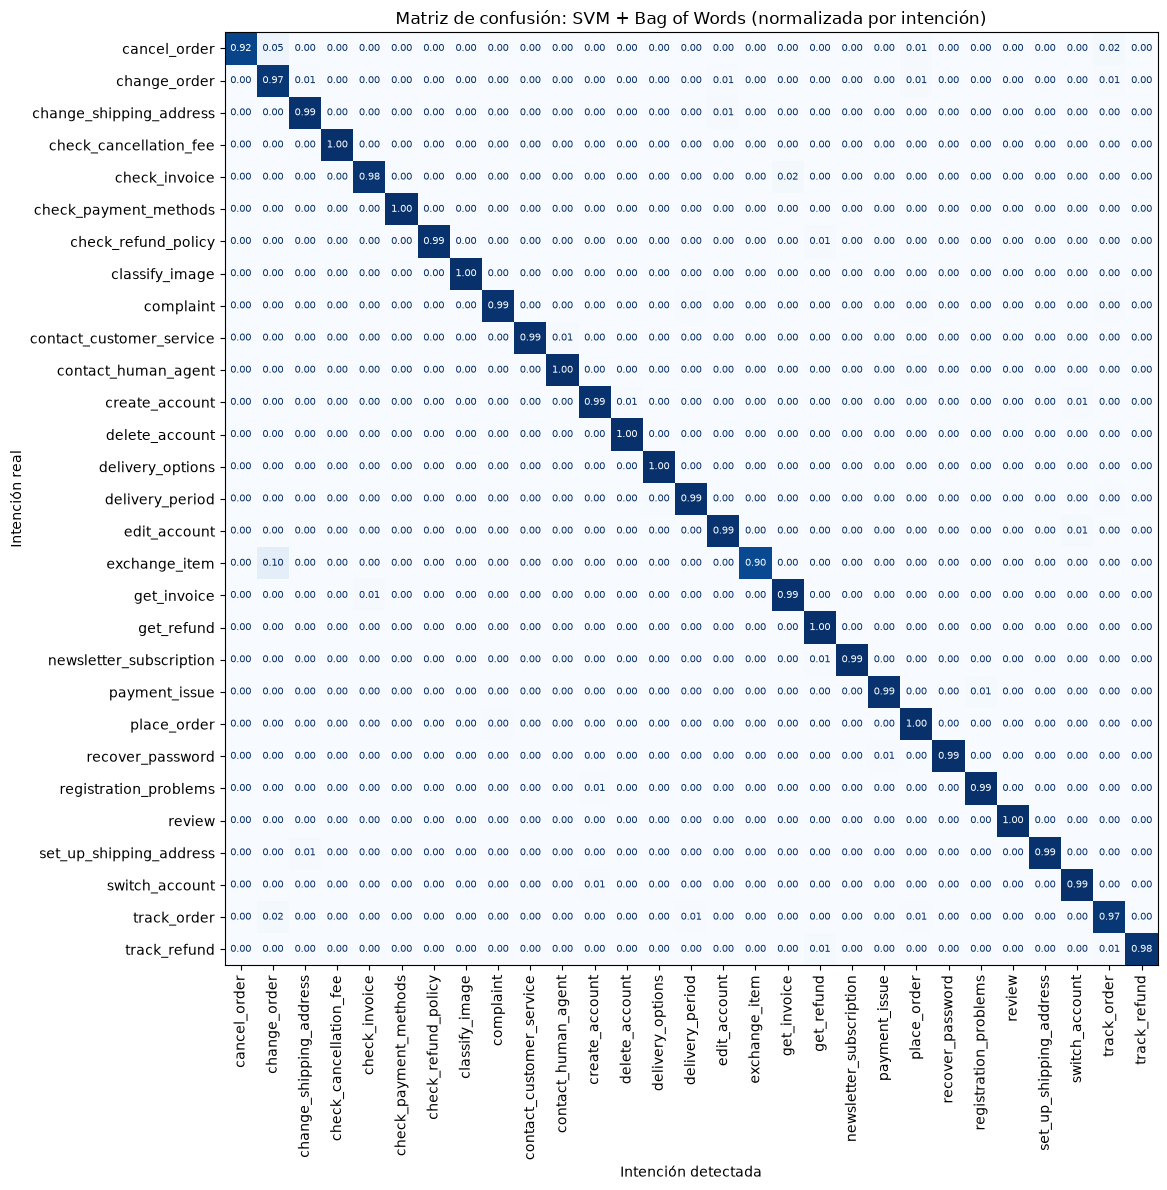

In [17]:
# ------------------------------------------------------------
# 5.4 Matriz de confusión
# ------------------------------------------------------------
# Filas: intención real | Columnas: intención detectada.
# Se normaliza por fila para ver el porcentaje de aciertos de cada intención.

etiquetas = sorted(intenciones.keys())
matriz = confusion_matrix(prueba_completa["intent"], pred_completa, labels=etiquetas, normalize="true")

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(matriz, display_labels=etiquetas).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, values_format=".2f", colorbar=False)
for texto in ax.texts:
    texto.set_fontsize(7)
ax.set_title(f"Matriz de confusión: {MODELO_ELEGIDO} (normalizada por intención)")
ax.set_xlabel("Intención detectada")
ax.set_ylabel("Intención real")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()

Las confusiones más frecuentes ocurren entre intenciones muy relacionadas, como cancel_order detectada como change_order (5 frases), check_invoice detectada como get_invoice (3) y track_order detectada como change_order (3), lo que tiene sentido porque un cliente puede usar palabras muy parecidas para pedir cosas distintas sobre el mismo pedido. Aun así, en la matriz de confusión casi toda la diagonal está cerca de 1, de forma que estos errores representan un porcentaje muy pequeño de cada intención.

In [18]:
# ------------------------------------------------------------
# 6. Detección de intención
# ------------------------------------------------------------

# Regla: probabilidad mínima para aceptar la intención que predice el modelo
UMBRAL = 0.4

def detectar_intencion(mensaje):
    """
    Detecta la intención con el modelo elegido en la sección 4. Devuelve intención y probabilidad.
    """
    # Si después del preprocesamiento no queda ninguna palabra, no hay nada que clasificar
    if not stems(mensaje):
        return "desconocida", 0

    # El modelo calcula la probabilidad de cada intención y se toma la más alta
    probabilidades = modelo.predict_proba(vectorizador.transform([mensaje]))[0]
    posicion = probabilidades.argmax()
    mejor_intencion = modelo.classes_[posicion]
    probabilidad = probabilidades[posicion]

    # Si el modelo no está seguro se toma como fuera del dominio
    if probabilidad < UMBRAL:
        return "desconocida", round(probabilidad, 2)

    return mejor_intencion, round(probabilidad, 2)

In [19]:
# ------------------------------------------------------------
# 7. Detección de casos sensibles
# ------------------------------------------------------------
# Regla de seguridad que revisa todos los mensajes, sin depender solo del clasificador,
# para que las quejas indirectas también lleguen a un agente humano.

analizador_sentimiento = SentimentIntensityAnalyzer()

# Sentimiento muy negativo según VADER (va de -1 a 1)
UMBRAL_SENTIMIENTO = -0.5

# Palabras y frases que indican molestia o un problema con el producto
PALABRAS_MOLESTIA = [
    "upset", "angry", "furious", "disappointed", "disappointing", "terrible", "awful",
    "horrible", "worst", "unacceptable", "ridiculous", "annoying", "annoyed", "frustrated",
    "frustrating", "broken", "damaged", "hole", "ripped", "torn", "faded", "dirty",
    "nobody", "no one", "never arrived", "still waiting", "wrong item", "not happy", "poor quality"
]

def detectar_caso_sensible(mensaje, intencion):
    """
    Indica si el mensaje debe pasar a un agente y el motivo.
    """
    if intencion in INTENCIONES_SENSIBLES:
        return True, "intención sensible"

    sentimiento = analizador_sentimiento.polarity_scores(mensaje)["compound"]
    if sentimiento <= UMBRAL_SENTIMIENTO:
        return True, f"sentimiento negativo ({sentimiento:.2f})"

    texto = normalizar_texto(mensaje)
    for palabra in PALABRAS_MOLESTIA:
        if re.search(rf"\b{re.escape(palabra)}\b", texto):
            return True, f"palabra de molestia: {palabra}"

    return False, ""

# Ejemplo con la queja de la conversación C08 de la primera entrega
queja = "I'm really upset, the shirt I got is the wrong size and nobody helps me"
print(detectar_caso_sensible(queja, detectar_intencion(queja)[0]))

(True, 'intención sensible')


In [20]:
# ------------------------------------------------------------
# 8. Detección básica de entidades
# ------------------------------------------------------------
# Catálogo de palabras clave por entidad: valor normalizado -> palabras que lo representan

catalogo_entidades = {
    "prenda": {
        "jacket": ["jacket", "coat", "hoodie", "sweater"],
        "shirt": ["shirt", "t-shirt", "tshirt", "blouse", "top"],
        "pants": ["pants", "jeans", "trousers", "shorts", "leggings"],
        "dress": ["dress", "skirt"],
        "shoes": ["shoes", "sneakers", "boots", "sandals"],
        "accessories": ["hat", "cap", "scarf", "belt", "bag"]
    },
    "talla": {
        "XS": ["xs", "extra small"],
        "S": ["small"],
        "M": ["medium"],
        "L": ["large"],
        "XL": ["xl", "extra large"]
    },
    "color": {
        "black": ["black"], "white": ["white"], "blue": ["blue", "navy"],
        "red": ["red"], "green": ["green"], "gray": ["gray", "grey"]
    },
    "metodo_pago": {
        "credit card": ["credit card", "debit card", "visa", "mastercard", "amex"],
        "paypal": ["paypal"],
        "apple pay": ["apple pay"]
    },
    "tipo_envio": {
        "standard": ["standard", "regular"],
        "express": ["express", "fast", "overnight"]
    }
}

def detectar_entidades(mensaje):
    """
    Detecta entidades mediante diccionario de términos y el número de pedido con regex.
    """
    texto = normalizar_texto(mensaje)
    entidades = {}

    # Se busca cada palabra clave como palabra completa y se guarda el primer valor encontrado
    for entidad, valores in catalogo_entidades.items():
        for valor, palabras_clave in valores.items():
            for palabra in palabras_clave:
                # \b evita coincidencias dentro de otras palabras ("red" en "registered")
                if re.search(rf"\b{re.escape(palabra)}\b", texto):
                    entidades[entidad] = valor
                    break
            if entidad in entidades:
                break

    # Número de pedido: "order 12345" o "#12345" (4 dígitos o más)
    pedido = re.search(r"(?:order|#)\s*#?\s*(\d{4,})", texto)
    if pedido:
        entidades["numero_pedido"] = pedido.group(1)

    return entidades

In [21]:
# ------------------------------------------------------------
# 8.1 Componente visual: clasificador de imágenes
# ------------------------------------------------------------
# Se carga el modelo guardado en el notebook del componente visual (modelo_visual.pt):
# EfficientNet-B0 preentrenada en ImageNet (congelada) con la capa nueva para las 10 clases de Fashion-MNIST.

punto_control = torch.load("modelo_visual.pt", map_location="cpu")
CLASES_VISUALES = punto_control["clases"]
CLASE_A_PRENDA = punto_control["clase_a_prenda"]

def crear_modelo_visual(n_clases):
    """
    Arma la misma estructura de red que se entrenó; los pesos se cargan después desde el archivo.
    """
    red_base = efficientnet_b0(weights=None)
    n_caracteristicas = red_base.classifier[1].in_features
    red_base.classifier = nn.Identity()
    cabeza = nn.Sequential(nn.Dropout(0.4), nn.Linear(n_caracteristicas, n_clases))
    return nn.Sequential(red_base, cabeza)

modelo_visual = crear_modelo_visual(len(CLASES_VISUALES))
modelo_visual.load_state_dict(punto_control["modelo"])
modelo_visual.eval()

# Misma preparación que en el entrenamiento
transformacion_visual = transforms.Compose([
    transforms.Resize(punto_control["tamano_imagen"]),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Probabilidad mínima para dar la clase como segura
UMBRAL_IMAGEN = 0.6

def preparar_imagen(ruta):
    """
    Convierte una foto al formato de Fashion-MNIST: escala de grises, prenda clara
    sobre fondo oscuro y 28x28 píxeles, y le aplica la transformación del modelo.
    """
    imagen = Image.open(ruta).convert("L")
    # Las fotos normales tienen fondo claro; se invierten para parecerse a Fashion-MNIST
    if np.asarray(imagen).mean() > 127:
        imagen = ImageOps.invert(imagen)
    imagen = ImageOps.pad(imagen, (28, 28), color=0)
    return transformacion_visual(imagen).unsqueeze(0)

def clasificar_imagen(ruta):
    """
    Devuelve la clase de Fashion-MNIST con mayor probabilidad y su probabilidad.
    """
    with torch.no_grad():
        salida = modelo_visual(preparar_imagen(ruta))
        probabilidades = torch.softmax(salida, dim=1)[0]
    posicion = int(probabilidades.argmax())
    return CLASES_VISUALES[posicion], float(probabilidades[posicion])

print(f"Modelo visual cargado: {punto_control['modelo_elegido']} ({punto_control['arquitectura']}) con {len(CLASES_VISUALES)} clases")

Modelo visual cargado: B. Con augmentation (efficientnet_b0) con 10 clases


El modelo visual que se carga es el modelo B con augmentation sobre EfficientNet-B0, el mismo que se evaluó en el notebook del componente visual, de forma que el chatbot usa exactamente la misma red, las mismas clases y la misma preparación de imagen.

In [22]:
# ------------------------------------------------------------
# 9. Generación de respuesta
# ------------------------------------------------------------

MENSAJE_FALLBACK = (
    "Sorry, I didn't catch that. Could you tell me what you need help with? "
    "I can help you with your orders, shipping, exchanges, returns and refunds, payments or your account."
)

def generar_respuesta(mensaje, prenda_contexto="item"):
    """
    Genera una respuesta considerando intención, reglas y entidades.
    prenda_contexto es la prenda identificada antes en una imagen, si la hay.
    """
    # Paso 1: intención con el modelo y entidades con el catálogo
    intencion, puntaje = detectar_intencion(mensaje)
    entidades = detectar_entidades(mensaje)

    # Paso 2: la regla de casos sensibles se revisa antes que todo lo demás
    sensible, motivo = detectar_caso_sensible(mensaje, intencion)
    if sensible:
        # Si la intención no es sensible se usa la respuesta de queja para avisar que pasa a un agente
        intencion_respuesta = intencion if intencion in INTENCIONES_SENSIBLES else "complaint"
        return {
            "intencion": intencion,
            "puntaje": puntaje,
            "accion": "canalizar_agente",
            "motivo": motivo,
            "entidades": entidades,
            "respuesta": random.choice(intenciones[intencion_respuesta]["respuestas"])
        }

    # Paso 3: si no se reconoce la intención se pide al cliente reformular
    if intencion == "desconocida":
        return {
            "intencion": intencion,
            "puntaje": puntaje,
            "accion": "fallback",
            "motivo": "probabilidad menor al umbral",
            "entidades": entidades,
            "respuesta": MENSAJE_FALLBACK
        }

    # Paso 4: si el cliente quiere identificar una imagen, se le pide la ruta del archivo
    if intencion == "classify_image":
        return {
            "intencion": intencion,
            "puntaje": puntaje,
            "accion": "solicitar_imagen",
            "motivo": "",
            "entidades": entidades,
            "respuesta": random.choice(intenciones[intencion]["respuestas"])
        }

    # Paso 5: se elige una de las respuestas de la intención
    plantilla = random.choice(intenciones[intencion]["respuestas"])

    # Paso 6: se rellenan los marcadores con los datos de la tienda y las entidades;
    # si el mensaje no menciona prenda se usa la identificada en la imagen
    valores = {**DATOS_TIENDA, "prenda": prenda_contexto, **entidades}
    respuesta = plantilla.format(**valores)

    return {
        "intencion": intencion,
        "puntaje": puntaje,
        "accion": "respuesta_automatica",
        "motivo": "",
        "entidades": entidades,
        "respuesta": respuesta
    }


# ------------------------------------------------------------
# 9.1 Respuesta del componente visual
# ------------------------------------------------------------

# Nombre de cada clase como se menciona en la respuesta al cliente
NOMBRE_CLASE = {
    "T-shirt/top": "t-shirt or top", "Trouser": "pair of trousers", "Pullover": "pullover",
    "Dress": "dress", "Coat": "coat", "Sandal": "sandal", "Shirt": "shirt",
    "Sneaker": "sneaker", "Bag": "bag", "Ankle boot": "ankle boot",
}

def con_articulo(nombre):
    """
    Agrega el artículo en inglés: "an" antes de vocal y "a" en otro caso.
    """
    if nombre[0] in "aeiou":
        return f"an {nombre}"
    return f"a {nombre}"

def responder_imagen(ruta):
    """
    Clasifica la imagen y comunica el resultado al cliente.
    """
    # Si el archivo no existe se le pide al cliente revisar la ruta
    if not os.path.isfile(ruta):
        return {
            "intencion": "classify_image",
            "puntaje": 0,
            "accion": "fallback",
            "clase": None,
            "motivo": "no se encontró la imagen",
            "entidades": {},
            "respuesta": "I couldn't find that image. Please check the path and type it again."
        }

    clase, probabilidad = clasificar_imagen(ruta)
    prenda = CLASE_A_PRENDA[clase]
    nombre = con_articulo(NOMBRE_CLASE[clase])

    if probabilidad >= UMBRAL_IMAGEN:
        respuesta = (f"It looks like {nombre} ({probabilidad:.0%} sure), from our {prenda} category. "
                     "Would you like to buy it, exchange it or return it?")
        accion = "clasificar_imagen"
    else:
        respuesta = (f"I'm not completely sure what this item is, my best guess is {nombre} ({probabilidad:.0%}). "
                     "Could you send a clearer photo of the item on a plain background?")
        accion = "clasificar_imagen_baja_confianza"

    return {
        "intencion": "classify_image",
        "puntaje": round(probabilidad, 2),
        "accion": accion,
        "clase": clase,
        "motivo": f"clase: {clase}",
        "entidades": {"prenda": prenda},
        "respuesta": respuesta
    }


# ------------------------------------------------------------
# 9.2 Procesamiento de cada mensaje (texto o imagen)
# ------------------------------------------------------------

def extraer_ruta_imagen(mensaje):
    """
    Busca en el mensaje una ruta a una imagen (.png, .jpg, .jpeg o .webp).
    """
    encontrada = re.search(r"\S+\.(?:png|jpe?g|webp)\b", mensaje, flags=re.IGNORECASE)
    if encontrada:
        return encontrada.group(0)
    return None

def procesar_mensaje(mensaje, estado):
    """
    Decide si el mensaje se responde con el componente conversacional o con el visual.
    estado guarda si el chatbot está esperando una imagen y la última prenda identificada.
    """
    ruta = extraer_ruta_imagen(mensaje)

    # Si el chatbot pidió una imagen, o el mensaje ya trae una ruta, se usa el componente visual
    if ruta or estado.get("esperando_imagen"):
        if ruta is None:
            ruta = mensaje.strip()
        resultado = responder_imagen(ruta)

        # Si no se encontró el archivo, se sigue esperando la imagen
        if resultado["accion"] == "fallback":
            estado["esperando_imagen"] = True
        else:
            estado["esperando_imagen"] = False
            # Se guarda la prenda identificada para usarla en los siguientes mensajes
            estado["prenda"] = resultado["entidades"]["prenda"]
        return resultado

    # En otro caso responde el componente conversacional
    resultado = generar_respuesta(mensaje, estado.get("prenda", "item"))
    resultado["clase"] = None

    # Si el cliente pidió identificar una imagen, el siguiente mensaje se toma como la ruta
    if resultado["accion"] == "solicitar_imagen":
        estado["esperando_imagen"] = True
    else:
        estado["esperando_imagen"] = False
    return resultado

Con estas funciones el chatbot ya funciona como un solo sistema, ya que procesar_mensaje revisa cada mensaje y decide qué componente lo responde: si el mensaje trae la ruta de una imagen, o si en el turno anterior el chatbot le pidió una imagen al cliente, se usa el componente visual, y en cualquier otro caso se usa el componente conversacional. Además, la prenda que se identifica en una imagen se guarda en el estado de la conversación, para así usarla en las respuestas siguientes aunque el cliente no vuelva a mencionarla.

In [23]:
# ------------------------------------------------------------
# 10. Chatbot interactivo
# ------------------------------------------------------------

SALUDO = [
    "Hi there! I'm the virtual assistant for our online clothing store.",
    "I can help you with your orders, shipping, exchanges, returns and refunds, payments or your account.",
    "I can also identify a clothing item from a photo, just ask me.",
    "Type 'exit' anytime to end the chat."
]
DESPEDIDA = "Thanks for chatting with us! Have a great day"

def iniciar_chatbot():
    """
    Ejecuta el chatbot en modo interactivo y devuelve el historial de la conversación.
    """
    historial = []
    estado = {}

    for linea in SALUDO:
        print(f"Chatbot: {linea}")
    print()

    while True:
        # En VS Code la caja para escribir aparece en la parte superior de la ventana
        mensaje_usuario = input("Usuario (escribe arriba y presiona Enter): ").strip()

        # Se muestra el mensaje en la salida para que se vea la conversación completa
        print(f"Usuario: {mensaje_usuario}")

        # Si no se escribe nada, se vuelve a pedir el mensaje
        if not mensaje_usuario:
            print("Chatbot: Please type a message, or 'exit' to end the chat.\n")
            continue

        # El cliente termina la conversación con exit o salir
        if normalizar_texto(mensaje_usuario) in ["exit", "salir"]:
            print(f"Chatbot: {DESPEDIDA}")
            break

        resultado = procesar_mensaje(mensaje_usuario, estado)

        # Se guarda cada turno para el análisis posterior
        historial.append({
            "mensaje_usuario": mensaje_usuario,
            "intencion_detectada": resultado["intencion"],
            "puntaje": resultado["puntaje"],
            "accion": resultado["accion"],
            "motivo": resultado["motivo"],
            "clase_imagen": resultado["clase"],
            "entidades": resultado["entidades"],
            "respuesta": resultado["respuesta"]
        })

        print(f"Chatbot: {resultado['respuesta']}\n")

    return pd.DataFrame(historial)

# Para platicar con el chatbot se quita el comentario de las siguientes líneas
# historial = iniciar_chatbot()
# historial

In [24]:
# ============================================================
# 11. Evaluación del chatbot
# ============================================================

# ------------------------------------------------------------
# 11.1 Evaluación con los conjuntos de prueba
# ------------------------------------------------------------
# Se evalúa el chatbot completo (modelo + umbral + regla de casos sensibles)

def accion_esperada(intent):
    if intent in INTENCIONES_SENSIBLES:
        return "canalizar_agente"
    if intent == "classify_image":
        return "solicitar_imagen"
    return "respuesta_automatica"

def evaluar_chatbot(datos):
    filas = []
    for _, fila in datos.iterrows():
        intencion, puntaje = detectar_intencion(fila["instruction"])
        sensible, motivo = detectar_caso_sensible(fila["instruction"], intencion)
        if sensible:
            accion = "canalizar_agente"
        elif intencion == "desconocida":
            accion = "fallback"
        else:
            accion = accion_esperada(intencion)
        filas.append({
            "mensaje": fila["instruction"],
            "intencion_esperada": fila["intent"],
            "intencion_detectada": intencion,
            "accion_esperada": accion_esperada(fila["intent"]),
            "accion": accion,
            "motivo": motivo,
        })
    return pd.DataFrame(filas)

for nombre, datos in [("Prueba del dataset (20 %)", prueba), ("Prueba del sector de ropa", prueba_ropa)]:
    res = evaluar_chatbot(datos)
    sensibles = res[res["accion_esperada"] == "canalizar_agente"]
    no_sensibles = res[res["accion_esperada"] == "respuesta_automatica"]
    print(nombre)
    print("------------------------")
    print(f"Frases: {len(res)}")
    print(f"Exactitud de intención: {(res['intencion_esperada'] == res['intencion_detectada']).mean():.2%}")
    print(f"Tasa de fallback: {(res['accion'] == 'fallback').mean():.2%}")
    print(f"Casos sensibles canalizados a un agente: {(sensibles['accion'] == 'canalizar_agente').mean():.2%}")
    print(f"Casos no sensibles canalizados por la regla: {(no_sensibles['accion'] == 'canalizar_agente').mean():.2%}\n")

Prueba del dataset (20 %)
------------------------
Frases: 4927
Exactitud de intención: 99.09%
Tasa de fallback: 0.14%
Casos sensibles canalizados a un agente: 99.49%
Casos no sensibles canalizados por la regla: 0.43%

Prueba del sector de ropa
------------------------
Frases: 79
Exactitud de intención: 83.54%
Tasa de fallback: 6.33%
Casos sensibles canalizados a un agente: 71.43%
Casos no sensibles canalizados por la regla: 1.64%



En la prueba del dataset el chatbot completo, considerando el umbral y la regla de casos sensibles, identifica correctamente el 99.09% de las intenciones, solo manda al fallback el 0.14% de los mensajes y canaliza a un agente el 99.49% de los casos sensibles. Con las frases de ropa la exactitud baja a 83.54% y el fallback sube a 6.33%, además de que solo se canaliza el 71.43% de los casos sensibles, por lo que las quejas indirectas escritas con vocabulario de ropa siguen siendo el punto más débil del chatbot y la principal oportunidad de mejora.

In [25]:
# ------------------------------------------------------------
# 11.2 Pruebas funcionales del chatbot integrado: texto e imagen
# ------------------------------------------------------------
# Cada conversación simula a un cliente distinto con varios mensajes seguidos, y todos los
# mensajes pasan por procesar_mensaje, que es la función que integra los dos componentes:
# si el mensaje trae la ruta de una imagen, o el chatbot acaba de pedir una, responde el
# componente visual, y en cualquier otro caso responde el componente conversacional.
# C01 a C10 son las conversaciones de la primera entrega y solo usan texto.
# C11 y C12 mezclan texto e imágenes en la misma conversación, usando las imágenes de imagenes_prueba:
#   C11: el cliente pide identificar una prenda, manda la foto y después pide un cambio,
#        y el chatbot usa la prenda detectada en la foto para armar la respuesta del cambio
#   C12: el cliente manda las fotos directamente en el mensaje y luego pregunta por el envío
# En los mensajes con imagen, la respuesta esperada es la clase correcta ("imagen:Dress").

conversaciones = {
    "C01 Pedido y cancelación": [
        ("I want to place an order", "place_order"),
        ("actually, how can I cancel order 48213?", "cancel_order"),
    ],
    "C02 Opciones y tiempos de envío": [
        ("what shipping options do you have?", "delivery_options"),
        ("how long does express delivery take", "delivery_period"),
    ],
    "C03 Reembolso de una prenda": [
        ("what is your refund policy?", "check_refund_policy"),
        ("I want a refund for my blue dress", "get_refund"),
        ("how can I track my refund?", "track_refund"),
    ],
    "C04 Cuenta de usuario": [
        ("I'd like to create an account", "create_account"),
        ("I forgot my password", "recover_password"),
        ("how do I update my profile?", "edit_account"),
    ],
    "C05 Pagos": [
        ("which payment methods do you accept?", "check_payment_methods"),
        ("my paypal payment didn't go through", "payment_issue"),
    ],
    "C06 Dirección de envío": [
        ("I need to change my shipping address", "change_shipping_address"),
        ("how do I add a new shipping address?", "set_up_shipping_address"),
    ],
    "C07 Facturas": [
        ("where can I check my invoice?", "check_invoice"),
        ("I need to download the invoice for order 55120", "get_invoice"),
    ],
    "C08 Queja y agente humano": [
        ("I'm really upset, the shirt I got is the wrong size and nobody helps me", "complaint"),
        ("can I talk to a real person please", "contact_human_agent"),
    ],
    "C09 Contacto, boletín y opinión": [
        ("how can I contact customer service?", "contact_customer_service"),
        ("I want to subscribe to your newsletter", "newsletter_subscription"),
        ("I'd like to leave a review for the sneakers I bought", "review"),
    ],
    "C10 Fuera de dominio y cuenta": [
        ("do you sell tacos & pizza?", "desconocida"),
        ("is there a fee if I cancel my order?", "check_cancellation_fee"),
        ("please delete my account", "delete_account"),
    ],
    "C11 Identificar una prenda y pedir un cambio": [
        ("could you tell me what item is in a picture I have?", "classify_image"),
        ("imagenes_prueba/dress_1.png", "imagen:Dress"),
        ("I'd like to exchange it for a bigger size", "exchange_item"),
    ],
    "C12 Imágenes directas y envío": [
        ("what is this? imagenes_prueba/sneaker_1.png", "imagen:Sneaker"),
        ("I also have this one imagenes_prueba/bag_1.png", "imagen:Bag"),
        ("how long would shipping take?", "delivery_period"),
    ],
}

def simular_conversacion(nombre, mensajes):
    """
    Ejecuta una conversación completa sin input() e imprime la transcripción.
    """
    print(f"===== {nombre} =====")
    for linea in SALUDO:
        print(f"Chatbot: {linea}")

    turnos = []
    estado = {}
    for mensaje, esperada in mensajes:
        resultado = procesar_mensaje(mensaje, estado)
        es_imagen = esperada.startswith("imagen:")
        print(f"\nUsuario: {mensaje}")
        print(f"Chatbot: {resultado['respuesta']}")
        print(f"  [intención: {resultado['intencion']} | probabilidad: {resultado['puntaje']} "
              f"| acción: {resultado['accion']} {resultado['motivo']} | entidades: {resultado['entidades']}]")
        turnos.append({
            "conversacion": nombre,
            "mensaje_usuario": mensaje,
            "intencion_esperada": esperada,
            "intencion_detectada": resultado["intencion"],
            "puntaje": resultado["puntaje"],
            "accion": resultado["accion"],
            "accion_correcta": resultado["accion"] == (
                "clasificar_imagen" if es_imagen else
                "fallback" if esperada == "desconocida" else accion_esperada(esperada)),
            "clase_imagen": resultado["clase"],
            "motivo": resultado["motivo"],
            "entidades": resultado["entidades"],
            "respuesta": resultado["respuesta"],
            "correcto": (resultado["clase"] == esperada.split(":")[1]) if es_imagen
                        else esperada == resultado["intencion"]
        })

    print("\nUsuario: exit")
    print(f"Chatbot: {DESPEDIDA}\n")
    return turnos

evidencias = []
for nombre, mensajes in conversaciones.items():
    evidencias.extend(simular_conversacion(nombre, mensajes))

df_evidencias = pd.DataFrame(evidencias)

# Se guardan las evidencias de ejecución en un archivo
df_evidencias.to_csv("evidencias_conversaciones.csv", index=False)

===== C01 Pedido y cancelación =====
Chatbot: Hi there! I'm the virtual assistant for our online clothing store.
Chatbot: I can help you with your orders, shipping, exchanges, returns and refunds, payments or your account.
Chatbot: I can also identify a clothing item from a photo, just ask me.
Chatbot: Type 'exit' anytime to end the chat.

Usuario: I want to place an order
Chatbot: Placing an order is easy! Add the items you like to your cart at www.ourstore.com, click 'Checkout' and follow the steps to choose your shipping and payment method.
  [intención: place_order | probabilidad: 0.95 | acción: respuesta_automatica  | entidades: {}]

Usuario: actually, how can I cancel order 48213?
Chatbot: You can cancel your order before your order ships. Go to 'My orders' at www.ourstore.com, select the order and click 'Cancel order'.
  [intención: cancel_order | probabilidad: 0.97 | acción: respuesta_automatica  | entidades: {'numero_pedido': '48213'}]

Usuario: exit
Chatbot: Thanks for chatti

In [26]:
# ------------------------------------------------------------
# 11.3 Resumen de las pruebas funcionales
# ------------------------------------------------------------

print(f"Conversaciones: {df_evidencias['conversacion'].nunique()}")
print(f"Mensajes evaluados: {len(df_evidencias)}")
print(f"Intenciones correctas: {df_evidencias['correcto'].sum()} de {len(df_evidencias)} "
      f"({df_evidencias['correcto'].mean():.2%})")
print(f"Acciones correctas: {df_evidencias['accion_correcta'].sum()} de {len(df_evidencias)} "
      f"({df_evidencias['accion_correcta'].mean():.2%})")
print(f"Mensajes canalizados a un agente: {(df_evidencias['accion'] == 'canalizar_agente').sum()}")
print(f"Mensajes con fallback: {(df_evidencias['accion'] == 'fallback').sum()}")

# Resultado por conversación
(df_evidencias.groupby("conversacion")
 .agg(mensajes=("correcto", "size"), intenciones_correctas=("correcto", "sum"),
      acciones_correctas=("accion_correcta", "sum"))
 .reset_index())

Conversaciones: 12
Mensajes evaluados: 30
Intenciones correctas: 30 de 30 (100.00%)
Acciones correctas: 30 de 30 (100.00%)
Mensajes canalizados a un agente: 4
Mensajes con fallback: 1


,conversacion,mensajes,intenciones_correctas,acciones_correctas
0,C01 Pedido y cancelación,2,2,2
1,C02 Opciones y tiempos de envío,2,2,2
2,C03 Reembolso de una prenda,3,3,3
3,C04 Cuenta de usuario,3,3,3
4,C05 Pagos,2,2,2
5,C06 Dirección de envío,2,2,2
6,C07 Facturas,2,2,2
7,C08 Queja y agente humano,2,2,2
8,"C09 Contacto, boletín y opinión",3,3,3
9,C10 Fuera de dominio y cuenta,3,3,3


Las 12 conversaciones se resolvieron correctamente, con 30 de 30 intenciones y acciones correctas, incluyendo los cuatro mensajes que se canalizaron a un agente y el mensaje fuera de dominio de C10, que terminó en fallback como se esperaba. En C11 se observa la integración completa de los dos componentes, ya que el chatbot detecta por texto que el cliente quiere identificar una prenda, le pide la imagen, la clasifica como vestido con 99% de seguridad y, cuando el cliente pide cambiarla por una talla más grande, responde con la política de cambios mencionando el vestido aunque el cliente nunca escribió la palabra dress, ya que la prenda se tomó de la imagen. En C12 el cliente manda las imágenes dentro del mensaje sin pedirlo antes, y el chatbot las reconoce directamente y después regresa al componente conversacional para responder sobre el envío.

In [27]:
# ------------------------------------------------------------
# 11.4 Prueba del componente visual dentro del chatbot
# ------------------------------------------------------------
# Se envían al chatbot, a través de procesar_mensaje, todas las imágenes de imagenes_prueba
# como si fueran fotos de clientes, y se compara la clase detectada con la clase real,
# que viene en el nombre del archivo.

NOMBRE_ARCHIVO_A_CLASE = {c.replace("/", "_").replace(" ", "_").lower(): c for c in CLASES_VISUALES}

filas = []
for archivo in sorted(os.listdir("imagenes_prueba")):
    clase_real = NOMBRE_ARCHIVO_A_CLASE[archivo.rsplit("_", 1)[0]]
    resultado = procesar_mensaje(f"imagenes_prueba/{archivo}", {})
    filas.append({
        "imagen": archivo,
        "clase_real": clase_real,
        "clase_detectada": resultado["clase"],
        "probabilidad": resultado["puntaje"],
        "prenda": resultado["entidades"].get("prenda"),
        "accion": resultado["accion"],
        "correcto": clase_real == resultado["clase"],
    })

df_imagenes = pd.DataFrame(filas)
print(f"Imágenes evaluadas: {len(df_imagenes)}")
print(f"Accuracy por clase: {df_imagenes['correcto'].mean():.2%}")
print(f"Respuestas con baja confianza: {(df_imagenes['accion'] == 'clasificar_imagen_baja_confianza').sum()}")

df_imagenes

Imágenes evaluadas: 20
Accuracy por clase: 95.00%
Respuestas con baja confianza: 2


,imagen,clase_real,clase_detectada,probabilidad,prenda,accion,correcto
0,ankle_boot_1.png,Ankle boot,Ankle boot,0.89,shoes,clasificar_imagen,True
1,ankle_boot_2.png,Ankle boot,Ankle boot,0.64,shoes,clasificar_imagen,True
2,bag_1.png,Bag,Bag,1.00,accessories,clasificar_imagen,True
3,bag_2.png,Bag,Bag,1.00,accessories,clasificar_imagen,True
4,coat_1.png,Coat,Coat,0.46,jacket,clasificar_imagen_baja_confianza,True
5,coat_2.png,Coat,Coat,0.77,jacket,clasificar_imagen,True
6,dress_1.png,Dress,Dress,0.99,dress,clasificar_imagen,True
7,dress_2.png,Dress,Dress,0.71,dress,clasificar_imagen,True
8,pullover_1.png,Pullover,Pullover,1.00,jacket,clasificar_imagen,True
9,pullover_2.png,Pullover,Pullover,0.98,jacket,clasificar_imagen,True


De las 20 imágenes de prueba, dos por cada clase, el chatbot clasificó correctamente 19, lo que da un 95% de aciertos, y el único error fue una playera detectada como Shirt con una probabilidad de 0.39, aunque ambas clases corresponden a la prenda shirt del catálogo. Como esa probabilidad queda por debajo del umbral de 0.6, el chatbot no le da la respuesta como segura al cliente sino que le pide una foto más clara, por lo que la regla del umbral evita que se le comunique una clasificación equivocada. Lo mismo ocurrió con un abrigo que sí se clasificó correctamente pero con una probabilidad de 0.46, en el que el chatbot compartió su mejor estimación y pidió una foto más clara para confirmarla.